Removed no burn in


Removed no burn in


Removed no burn in
Removed no burn in


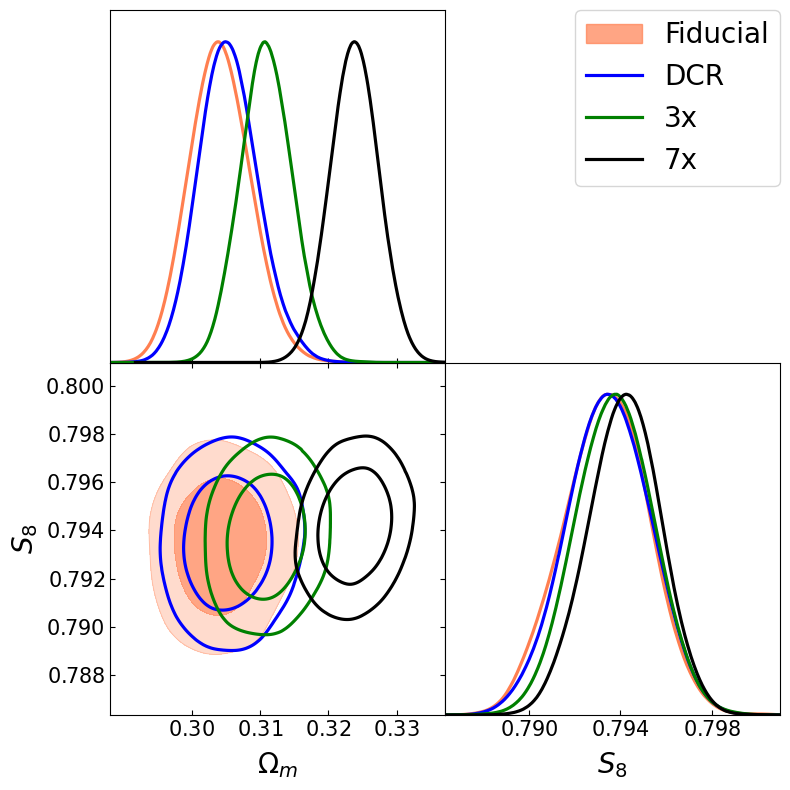

In [3]:

import getdist
from getdist import plots, MCSamples
from getdist.paramnames import escapeLatex, makeList, mergeRenames
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
%matplotlib inline


g = plots.getSubplotPlotter(width_inch=8)
newfidA = Path.home() / 'weaklens' / 'cosmolib' / 'output' / 'shrihan-clean-lsst-y10-fidA-nautilus.txt'
newfidB = Path.home() / 'weaklens' / 'cosmolib' / 'output' / 'shrihan-clean-lsst-y10-dcrA-nautilus.txt'
newfidC = Path.home() / 'weaklens' / 'cosmolib' / 'output' / 'shrihan-clean-lsst-y10-dcrA3x-nautilus.txt'
newfidD = Path.home() / 'weaklens' / 'cosmolib' / 'output' / 'shrihan-clean-lsst-y10-dcrA7x-nautilus.txt'


#imprintresp = Path.home() / 'weaklens' / 'cosmolib' / 'output' / 'des-y3-response2_A.txt'
newfidA_chains = np.genfromtxt(newfidA, names=True)
newfidB_chains = np.genfromtxt(newfidB, names=True)
newfidC_chains = np.genfromtxt(newfidC, names=True)
newfidD_chains = np.genfromtxt(newfidD, names=True)

omm = 0.#,#0.03
oss = 0.#,#0.03

uu = newfidA_chains
newfidA_samples = MCSamples(samples=np.c_[uu['cosmological_parametersomega_m']+omm,uu['COSMOLOGICAL_PARAMETERSSIGMA_8'],
                                (uu['COSMOLOGICAL_PARAMETERSSIGMA_8'])*np.sqrt((uu['cosmological_parametersomega_m'])/0.3)+oss,
                                 uu['cosmological_parametersn_s'], uu['cosmological_parametersomega_b'], uu['cosmological_parametersh0']],
                                 weights=np.exp(uu['log_weight']), names = ['Om','sigma8','s8','ns', 'Ob', 'h0'], labels = ['\Omega_{m}','\sigma_8','S_8','n_s','\Omega_b', 'h'])


uu = newfidB_chains
newfidB_samples = MCSamples(samples=np.c_[uu['cosmological_parametersomega_m']+omm,uu['COSMOLOGICAL_PARAMETERSSIGMA_8'],
                                (uu['COSMOLOGICAL_PARAMETERSSIGMA_8'])*np.sqrt((uu['cosmological_parametersomega_m'])/0.3)+oss,
                                 uu['cosmological_parametersn_s'], uu['cosmological_parametersomega_b'], uu['cosmological_parametersh0']],
                                 weights=np.exp(uu['log_weight']), names = ['Om','sigma8','s8','ns', 'Ob', 'h0'], labels = ['\Omega_{m}','\sigma_8','S_8','n_s','\Omega_b', 'h'])

uu = newfidC_chains
newfidC_samples = MCSamples(samples=np.c_[uu['cosmological_parametersomega_m']+omm,uu['COSMOLOGICAL_PARAMETERSSIGMA_8'],
                                (uu['COSMOLOGICAL_PARAMETERSSIGMA_8'])*np.sqrt((uu['cosmological_parametersomega_m'])/0.3)+oss,
                                 uu['cosmological_parametersn_s'], uu['cosmological_parametersomega_b'], uu['cosmological_parametersh0']],
                                 weights=np.exp(uu['log_weight']), names = ['Om','sigma8','s8','ns', 'Ob', 'h0'], labels = ['\Omega_{m}','\sigma_8','S_8','n_s','\Omega_b', 'h'])


uu = newfidD_chains
newfidD_samples = MCSamples(samples=np.c_[uu['cosmological_parametersomega_m']+omm,uu['COSMOLOGICAL_PARAMETERSSIGMA_8'],
                                (uu['COSMOLOGICAL_PARAMETERSSIGMA_8'])*np.sqrt((uu['cosmological_parametersomega_m'])/0.3)+oss,
                                 uu['cosmological_parametersn_s'], uu['cosmological_parametersomega_b'], uu['cosmological_parametersh0']],
                                 weights=np.exp(uu['log_weight']), names = ['Om','sigma8','s8','ns', 'Ob', 'h0'], labels = ['\Omega_{m}','\sigma_8','S_8','n_s','\Omega_b', 'h'])



g.settings.axes_labelsize = 20
g.settings.axes_fontsize =15
g.settings.legend_fontsize = 20
g.settings.linewidth = 2

g.triangle_plot(
    [newfidA_samples, newfidB_samples, newfidC_samples, newfidD_samples],
    ['Om', 's8'],
    filled=[True, False, False, False, True, True],
    colors=['coral', 'blue', 'green', 'black', 'black', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0, 0.5, 0.5],
    legend_labels=['Fiducial', 'DCR', '3x', '7x'],  # Turn off legend
    legend_loc='upper right',
    fontsize=40,
    contour_colors=['coral', 'blue', 'green', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-']
)


Removed no burn in
Removed no burn in


Removed no burn in
Removed no burn in


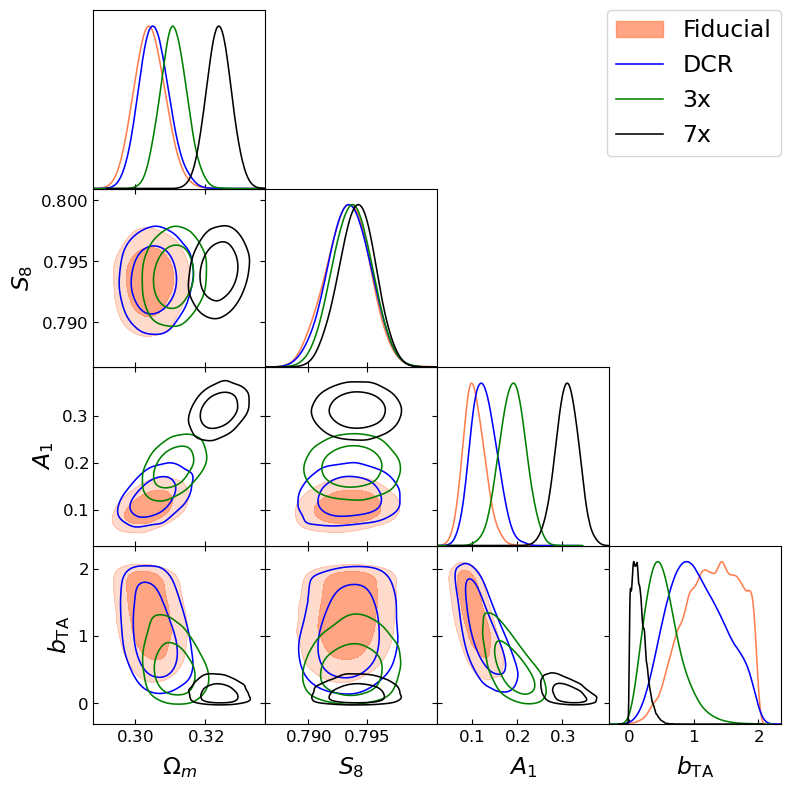

In [4]:
def make_samples(uu):
    om  = uu['cosmological_parametersomega_m']
    sig = uu['COSMOLOGICAL_PARAMETERSSIGMA_8']
    return MCSamples(
        samples=np.c_[
            om + omm,
            sig,
            sig * np.sqrt(om / 0.3) + oss,
            uu['cosmological_parametersn_s'],
            uu['cosmological_parametersomega_b'],
            uu['cosmological_parametersh0'],
            uu['intrinsic_alignment_parametersa1'],
            uu['intrinsic_alignment_parametersbias_ta'],
        ],
        weights=np.exp(uu['log_weight']),
        names =['Om', 'sigma8', 's8', 'ns', 'Ob', 'h0', 'a1', 'bias_ta'],
        labels=[r'\Omega_{m}', r'\sigma_8', r'S_8', r'n_s', r'\Omega_b', r'h',
                r'A_1', r'b_{\rm TA}'],
    )

newfidA_samples = make_samples(newfidA_chains)
newfidB_samples = make_samples(newfidB_chains)
newfidC_samples = make_samples(newfidC_chains)
newfidD_samples = make_samples(newfidD_chains)

g.settings.axes_labelsize  = 20
g.settings.axes_fontsize   = 15
g.settings.legend_fontsize = 20
g.settings.linewidth       = 2

g.triangle_plot(
    [newfidA_samples, newfidB_samples, newfidC_samples, newfidD_samples],
    ['Om', 's8', 'a1', 'bias_ta'],
    filled=[True, False, False, False],
    colors=['coral', 'blue', 'green', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0],
    legend_labels=['Fiducial', 'DCR', '3x', '7x'],
    legend_loc='upper right',
    fontsize=40,
    contour_colors=['coral', 'blue', 'green', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-'],
)

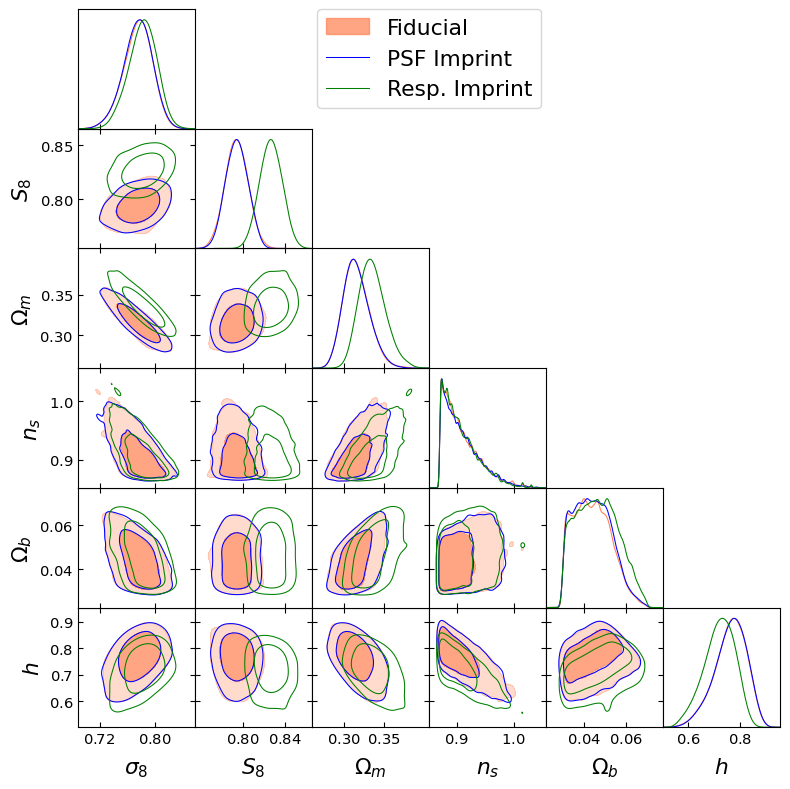

In [7]:
g.triangle_plot(
    [newfidA_samples, newfidB_samples, newfidC_samples], #newfidD_samples],
    ['sigma8', 's8', 'Om', 'ns', 'Ob', 'h0'],
    filled=[True, False, False, False, True, True],
    colors=['coral', 'blue', 'green', 'black', 'black', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0, 0.5, 0.5],
    legend_labels=['Fiducial', 'PSF Imprint', 'Resp. Imprint', 'DCR Imprint'],  # Turn off legend
    legend_loc=None,
    fontsize=40,
    contour_colors=['coral', 'blue', 'green', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-']
)
plt.savefig('LSSTY1_All_Imprints.png', dpi=600, bbox_inches='tight', transparent=True)

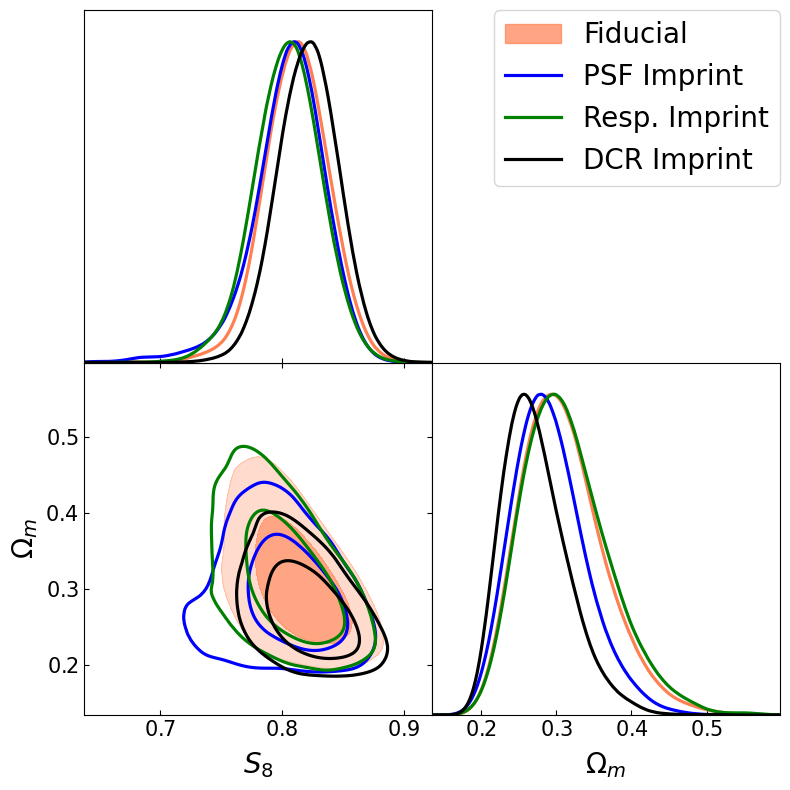

In [7]:
g.triangle_plot(
    [newfidA_samples, newfidB_samples, newfidC_samples, newfidD_samples],
    ['s8', 'Om'],
    filled=[True, False, False, False, True, True],
    colors=['coral', 'blue', 'green', 'black', 'black', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0, 0.5, 0.5],
    legend_labels=['Fiducial', 'PSF Imprint', 'Resp. Imprint', 'DCR Imprint'],  # Turn off legend
    legend_loc='upper right',
    fontsize=40,
    contour_colors=['coral', 'blue', 'green', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-']
)
#plt.savefig('DECADE_PSF_Imprints.png', dpi=600, bbox_inches='tight', transparent=True)

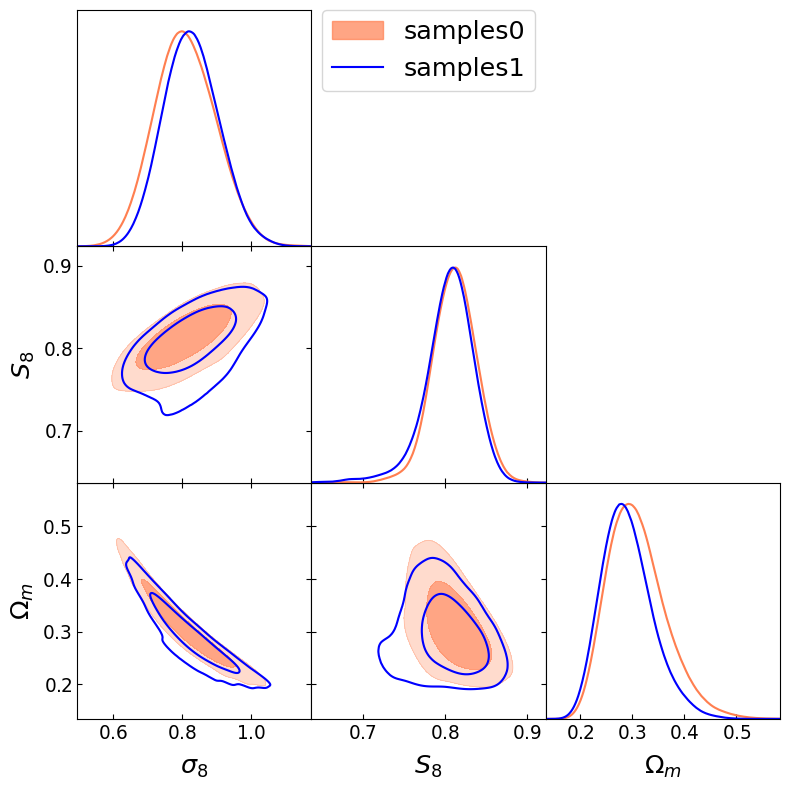

In [15]:
g.triangle_plot(
    [newfidA_samples, newfidB_samples],
    ['sigma8', 's8', 'Om'],
    filled=[True, False, False, False, True, True],
    colors=['coral', 'blue', 'green', 'black', 'black', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0, 0.5, 0.5],
    legend_labels=None,  # Turn off legend
    legend_loc='upper center',
    fontsize=40,
    contour_colors=['coral', 'blue', 'green', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-']
)
plt.savefig('DECADE_PSF_Imprints.png', dpi=600, bbox_inches='tight', transparent=True)

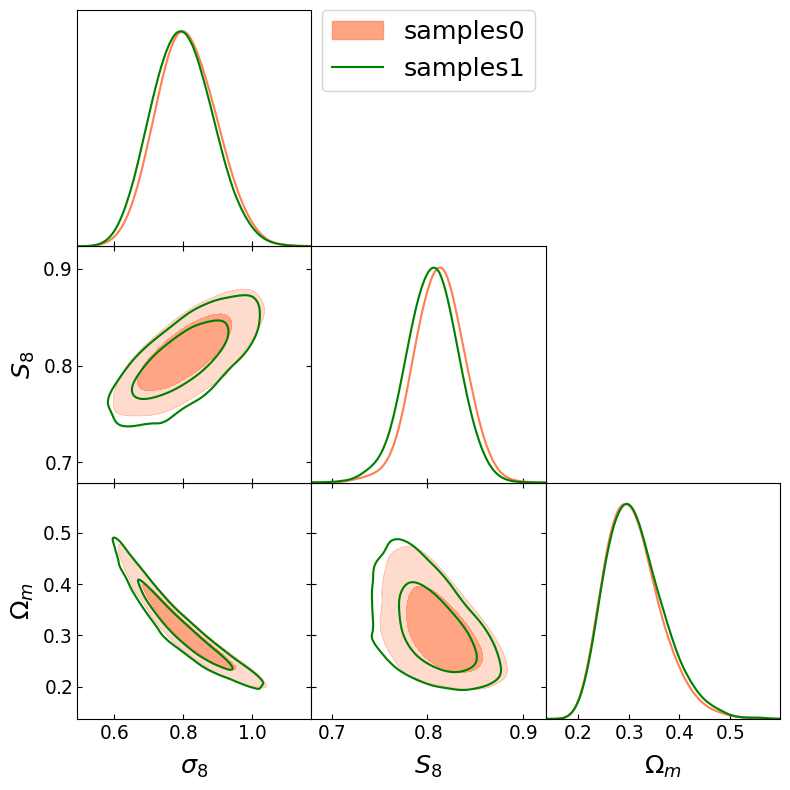

In [14]:
g.triangle_plot(
    [newfidA_samples, newfidC_samples],
    ['sigma8', 's8', 'Om'],
    filled=[True, False, False, False, True, True],
    colors=['coral', 'green', 'black', 'black', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0, 0.5, 0.5],
    legend_labels=None,  # Turn off legend
    legend_loc='upper center',
    fontsize=40,
    contour_colors=['coral', 'green', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-']
)
plt.savefig('DECADE_Response_Imprints.png', dpi=600, bbox_inches='tight', transparent=True)

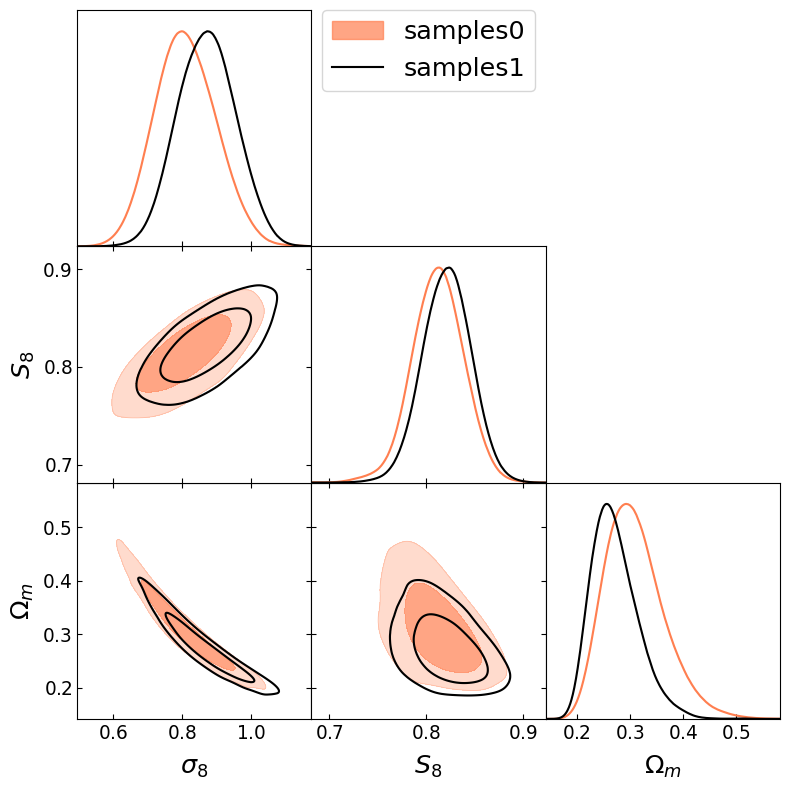

In [17]:
g.triangle_plot(
    [newfidA_samples, newfidD_samples],
    ['sigma8', 's8', 'Om'],
    filled=[True, False, False, False, True, True],
    colors=['coral',  'black', 'black', 'black'],
    alphas=[0.7, 1.0, 1.0, 1.0, 0.5, 0.5],
    legend_labels=None,  # Turn off legend
    legend_loc='upper center',
    fontsize=40,
    contour_colors=['coral', 'black'],
    ls=['-', '-', '-', '-'],
    contour_ls=['-', '-', '-', '-']
)
plt.savefig('DECADE_DCR_Imprints.png', dpi=600, bbox_inches='tight', transparent=True)